In [1]:
%matplotlib inline

from collections import OrderedDict
from importlib import reload
import os, sys

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.cm as cm

import numpy as np
import pandas as pd
import scipy.stats

from astropy.table import Table, vstack, join
from astropy.stats import mad_std
from astropy.constants import iau2012 as const

from scipy.stats import spearmanr, gaussian_kde
import statsmodels.api as sm

sys.path.append('../')
from aklpyutils.utils_stats import *
from aklpyutils.utils_spacing import *


from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import MaxNLocator
from shapely.geometry import Point
from shapely.ops import cascaded_union

from jsplottools.sun_plot_tools.general import mpl_setup
from jsplottools.sun_plot_tools.ax import *
from jsplottools.sun_plot_tools.fig import *
mpl_setup(figtype='paper-1/3')
params = {'legend.fontsize': 'x-large',          
         'axes.labelsize': 'x-large',
         'axes.titlesize':'x-large',
         'xtick.labelsize':'x-large',
         'ytick.labelsize':'x-large'}
plt.rcParams.update(params)

In [2]:
from key_dirs import *
from aklpyutils.utils_spacing import *

# change the fiducial source list
source_nthresh = ['ngc0300','ngc3489','ngc4459', 'ngc4476', 'ngc4477', 'ngc4596', 'ngc4731', 'ngc4826', 'ngc7456', 'ngc7793']
# source_list = [source for source in source_list if source not in source_nthresh]

# import the sample table
# Sample table
sample_tab_file = '../phangs_sample_table_v1p6.fits'
sample_tab = Table.read(sample_tab_file)
sample_tab['name'][0] = 'circinus'

['ic1954', 'ic5273', 'ngc0253', 'ngc0300', 'ngc0628', 'ngc0685', 'ngc1097', 'ngc1511', 'ngc1546', 'ngc1637', 'ngc1792', 'ngc2903', 'ngc2997', 'ngc3137', 'ngc3351', 'ngc3489', 'ngc3511', 'ngc3521', 'ngc3621', 'ngc3627', 'ngc4254', 'ngc4298', 'ngc4459', 'ngc4476', 'ngc4477', 'ngc4536', 'ngc4548', 'ngc4569', 'ngc4596', 'ngc4731', 'ngc4781', 'ngc4826', 'ngc4941', 'ngc5068', 'ngc5128', 'ngc5236', 'ngc5643', 'ngc7456', 'ngc7496', 'ngc7793']


**Spacing vs. Resolution**

In [3]:
spacing_list = []
res_list = []
noise_list = []
native_list = []

spacing_dict = {}

matched_list = [
    '../cloud_cats_fits/matched_120pc_props/',
    '../cloud_cats_fits/matched_150pc_props/',
#     '../cloud_cats_fits/matched_200pc_props/',
    '../cloud_cats_fits/matched_60pc_props/',
    '../cloud_cats_fits/matched_90pc_props/',
    ]
lownoise_list = [
    '../cloud_cats_fits/homogen_hi_120pc_props/',
    '../cloud_cats_fits/homogen_hi_150pc_props/',
#     '../cloud_cats_fits/homogen_hi_200pc_props/',
    '../cloud_cats_fits/homogen_hi_60pc_props/',
    '../cloud_cats_fits/homogen_hi_90pc_props/',
    ]
highnoise_list = [
    '../cloud_cats_fits/homogen_lo_120pc_props/',
    '../cloud_cats_fits/homogen_lo_150pc_props/',
#     '../cloud_cats_fits/homogen_lo_200pc_props/',
    '../cloud_cats_fits/homogen_lo_60pc_props/',
    '../cloud_cats_fits/homogen_lo_90pc_props/',
    ]

for this_cat_dir in cat_dir_list:

    in_dir = cat_root_dir + this_cat_dir+'/'
    print(in_dir)
    
    # Find all catalogs in the directory
    cat_glob = glob.glob(in_dir+'*_props.fits')

    sub_spacing_list = []
    sub_res_list = []
    sub_noise_list = []
    sub_native_list = []

    for in_cat_file in cat_glob:
        
        out_cat_file = in_cat_file.replace('_props.fits','_props_valueadded.fits')
        cat = Table.read(out_cat_file)
            
        spacing_vec = np.array(cat['DIST_NN1_PC'])        
        spacing_list.append(spacing_vec)
        sub_spacing_list.append(spacing_vec)
        
        res_vec = np.array(cat['BEAMMAJ_PC'])        
        res_list.append(res_vec)
        sub_res_list.append(res_vec)
        
        noise_vec = np.array(cat['TMAX_K'])/np.array(cat['S2N'])
        noise_list.append(noise_vec)
        sub_noise_list.append(noise_vec)
        
        native_vec = np.zeros_like(noise_vec) + (in_dir.count('native') >= 1)
        native_list.append(native_vec)
        sub_native_list.append(native_vec)
        
        if (in_dir.count('native') >= 1):
            this_spacing_dict = calc_stats(spacing_vec, doprint=False)
            this_spacing_dict['MED_RES_PC'] = np.median(res_vec)
            this_spacing_dict['IS_NATIVE'] = True        
            this_spacing_dict['IS_HIGHNOISE'] = False
            this_spacing_dict['IS_LOWNOISE'] = False
            this_spacing_dict['IS_MATCHED'] = False    
            spacing_dict[out_cat_file] = this_spacing_dict        
            
    sub_noise_vec = np.concatenate(sub_noise_list)
    sub_spacing_vec = np.concatenate(sub_spacing_list)
    sub_res_vec = np.concatenate(sub_res_list)
    sub_native_vec = np.concatenate(sub_native_list)
    
    this_spacing_dict = calc_stats(sub_spacing_vec, doprint=False)
    this_spacing_dict['MED_RES_PC'] = np.median(sub_res_vec)
    this_spacing_dict['IS_NATIVE'] = (in_dir.count('native') >= 1)        
    this_spacing_dict['IS_HIGHNOISE'] = (in_dir in highnoise_list)        
    this_spacing_dict['IS_LOWNOISE'] = (in_dir in lownoise_list)        
    this_spacing_dict['IS_MATCHED'] = (in_dir in matched_list)        
    spacing_dict[in_dir] = this_spacing_dict        
            
noise_vec = np.concatenate(noise_list)
spacing_vec = np.concatenate(spacing_list)
res_vec = np.concatenate(res_list)
native_vec = np.concatenate(native_list)    

../cloud_cats_fits/homogen_lo_120pc_props/
../cloud_cats_fits/homogen_hi_120pc_props/
../cloud_cats_fits/homogen_lo_150pc_props/
../cloud_cats_fits/homogen_hi_150pc_props/
../cloud_cats_fits/homogen_lo_60pc_props/
../cloud_cats_fits/homogen_hi_60pc_props/
../cloud_cats_fits/homogen_lo_90pc_props/
../cloud_cats_fits/homogen_hi_90pc_props/
../cloud_cats_fits/matched_120pc_props/
../cloud_cats_fits/matched_150pc_props/
../cloud_cats_fits/matched_60pc_props/
../cloud_cats_fits/matched_90pc_props/
../cloud_cats_fits/native_props/


In [4]:
fid_cat_tabs = {}
fid_cat_stats = {}
dist_1st_arr_50 = np.array([]); dist_1st_arr_16 = np.array([]); dist_1st_arr_84 = np.array([])
dist_5th_arr_50 = np.array([]); dist_5th_arr_16 = np.array([]); dist_5th_arr_84 = np.array([])
n_neighb_500pc_means = np.array([]); n_neighb_750pc_means = np.array([])
N_GMCs_arr = np.array([]); lstar_arr = np.array([])
source_name_list = np.array([])


for this_source in source_list:
    this_fid_cat = fid_cat_dict[this_source].replace('_props.fits','_props_valueadded.fits')
    # print(this_fid_cat)
    fid_cat_tabs[this_source] = Table.read(this_fid_cat)
    N_GMCs_arr = np.append(N_GMCs_arr, len(fid_cat_tabs[this_source]))
    stat_dict = {}
    # get the sample table for 
    source_info = sample_tab[int(np.where(sample_tab['name'] == this_source)[0])]
    deg_to_pc = float(np.pi/180.*source_info['dist']*1e3)
    lstar = float(source_info['size_scalelength']/3600.*deg_to_pc)
    lstar_arr = np.append(lstar_arr, np.round(lstar, 1))
    dist_1st = np.array(fid_cat_tabs[this_source]['DIST_NN1_PC'])
    stat_dict['dist_1st_50'] = np.nanmedian(dist_1st); dist_1st_arr_50 = np.append(dist_1st_arr_50, np.nanmedian(dist_1st))
    stat_dict['dist_1st_16'] = np.nanpercentile(dist_1st, 16); dist_1st_arr_16 = np.append(dist_1st_arr_16, np.nanpercentile(dist_1st, 16))
    stat_dict['dist_1st_84'] = np.nanpercentile(dist_1st, 84); dist_1st_arr_84 = np.append(dist_1st_arr_84, np.nanpercentile(dist_1st, 84))
    dist_5th = np.array(fid_cat_tabs[this_source]['DIST_NN5_PC'])
    stat_dict['dist_5th_50'] = np.nanmedian(dist_5th); dist_5th_arr_50 = np.append(dist_5th_arr_50, np.nanmedian(dist_5th))
    stat_dict['dist_5th_16'] = np.nanpercentile(dist_5th, 16); dist_5th_arr_16 = np.append(dist_5th_arr_16, np.nanpercentile(dist_5th, 16))
    stat_dict['dist_5th_84'] = np.nanpercentile(dist_5th, 84); dist_5th_arr_84 = np.append(dist_5th_arr_84, np.nanpercentile(dist_5th, 84))
    n_neighb_500pc = np.array(fid_cat_tabs[this_source]['NEIGHBORS_500PC'])
    stat_dict['nn_500pc_mean'] = np.nanmean(n_neighb_500pc); n_neighb_500pc_means = np.append(n_neighb_500pc_means, stat_dict['nn_500pc_mean'])
    n_neighb_750pc = np.array(fid_cat_tabs[this_source]['NEIGHBORS_750PC'])
    stat_dict['nn_750pc_mean'] = np.nanmean(n_neighb_750pc); n_neighb_750pc_means = np.append(n_neighb_750pc_means, stat_dict['nn_750pc_mean'])
    source_name_list = np.append(source_name_list, this_source.upper())
    

stats_tab = Table()
stats_tab['galaxy'] = source_name_list
stats_tab['N_GMCs'] = N_GMCs_arr.astype(int)
stats_tab['lstar'] = lstar_arr
stats_tab['dist_1st_16'] = np.round(dist_1st_arr_16, 1); stats_tab['dist_1st_50'] = np.round(dist_1st_arr_50, 1);  stats_tab['dist_1st_84'] = np.round(dist_1st_arr_84, 1)
stats_tab['dist_5th_16'] = np.round(dist_5th_arr_16, 1); stats_tab['dist_5th_50'] = np.round(dist_5th_arr_50, 1); stats_tab['dist_5th_84'] = np.round(dist_5th_arr_84, 1)
stats_tab['nn_500pc_mean'] = np.round(n_neighb_500pc_means,1); stats_tab['nn_750pc_mean'] = np.round(n_neighb_750pc_means,1)

stats_tab["galaxy"] = stats_tab["galaxy"].astype("<U8")
for this_source in source_nthresh:
    idx = np.where(stats_tab['galaxy']==this_source.upper())
    stats_tab['galaxy'][idx] = this_source.upper()+'*'

latex_code = stats_tab.write(filename='../tables/table1.tex', format='latex', overwrite=True)

stats_tab.write('../tables/spacing_nn.fits', format='fits', overwrite=True)

display(stats_tab)

galaxy,N_GMCs,lstar,dist_1st_16,dist_1st_50,dist_1st_84,dist_5th_16,dist_5th_50,dist_5th_84,nn_500pc_mean,nn_750pc_mean
str8,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64
IC1954,94,1.5,236.2,474.7,808.4,751.9,1128.7,2079.4,0.9,2.3
IC5273,79,1.3,262.2,549.4,959.5,827.3,1368.9,2218.4,0.7,1.9
NGC0253,481,2.8,196.6,449.8,877.0,722.2,1271.8,1947.4,1.4,2.7
NGC0300*,9,1.3,688.4,1113.9,1449.9,2806.2,3244.4,3830.1,0.1,0.2
NGC0628,271,2.9,277.4,465.8,772.8,805.1,1154.7,1785.0,0.8,2.0
NGC0685,151,3.1,259.3,509.9,1026.0,959.2,1414.2,2396.2,0.7,1.5
NGC1097,344,4.3,213.3,415.3,847.6,729.4,1259.9,2047.4,1.2,2.5
NGC1511,110,1.7,267.5,513.2,972.8,921.9,1358.0,2157.6,0.7,1.7
NGC1546,117,2.1,212.2,425.0,798.0,738.9,1071.4,1629.4,1.0,2.4


In [5]:
noise_vec = np.concatenate(noise_list)
spacing_vec = np.concatenate(spacing_list)
res_vec = np.concatenate(res_list)
native_vec = np.concatenate(native_list)
print(len(noise_vec), len(spacing_vec), len(res_vec), len(native_vec))

164238 164238 164238 164238


In [6]:
source_list_ra = np.array(source_list)

mass_ra = np.zeros(len(source_list_ra))
lco_ra = np.zeros(len(source_list_ra))
sfr_ra = np.zeros(len(source_list_ra))
lstar_ra = np.zeros(len(source_list_ra))
incl_ra = np.zeros(len(source_list_ra))

for ii, this_source in enumerate(source_list_ra):
    deets = deets_dict[this_source]
    mass_ra[ii] = float(deets['props_mstar'])
    sfr_ra[ii] = float(deets['props_sfr'])
    lco_ra[ii] = float(deets['lco_phangs'])
    incl_ra[ii] = float(deets['orient_incl'])
    deg_to_pc = float(np.pi/180.*deets['dist']*1e3)
    lstar_ra[ii] = float(deets['size_scalelength']/3600.*deg_to_pc)        
        
mass_order = np.argsort(mass_ra)
lco_order = np.argsort(lco_ra)
sfr_order = np.argsort(sfr_ra)
lstar_order = np.argsort(lstar_ra)

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/2344690063.py:13: UserWarning: Warning: converting a masked element to nan.
  lco_ra[ii] = float(deets['lco_phangs'])


Make a table of the spacing, number of nearest neighbors, etc...

**Plot resolution vs spacing**....

In [7]:
x_list = []
y_list = []

for this_key in spacing_dict.keys():    
    this_spacing_dict = spacing_dict[this_key]
    if this_spacing_dict['IS_NATIVE'] == False:
        continue
    this_x = np.log10(this_spacing_dict['MED_RES_PC'])
    this_y = np.log10(this_spacing_dict['50'])
    x_list.append(this_x)
    y_list.append(this_y)

x_vec = np.array(x_list)
y_vec = np.array(y_list)
ind = np.isfinite(x_vec)*np.isfinite(y_vec)
x_vec = x_vec[ind]
y_vec = y_vec[ind]

print("Native resolution numbers for nearest_neighbor spacing:")
print("Median diff [log]: ", np.nanmedian(y_vec-x_vec))
print("Median diff [linear]: ", 10.**np.nanmedian(y_vec-x_vec))
print("Rank correlation: ", scipy.stats.spearmanr(x_vec,y_vec))

# do the same thing for high sensitivity data
x_list = []
y_list = []

for this_key in spacing_dict.keys():    
    this_spacing_dict = spacing_dict[this_key]
    if this_spacing_dict['IS_LOWNOISE'] == False:
        continue
    this_x = np.log10(this_spacing_dict['MED_RES_PC'])
    this_y = np.log10(this_spacing_dict['50'])
    x_list.append(this_x)
    y_list.append(this_y)

x_vec = np.array(x_list)
y_vec = np.array(y_list)
ind = np.isfinite(x_vec)*np.isfinite(y_vec)
x_vec = x_vec[ind]
y_vec = y_vec[ind]

print("High sensitivity homogenized dataset:")
print("Median diff [log]: ", np.nanmedian(y_vec-x_vec))
print("Median diff [linear]: ", 10.**np.nanmedian(y_vec-x_vec))
print("Rank correlation: ", scipy.stats.spearmanr(x_vec,y_vec))

# do the same thing for low sensitivity data
x_list = []
y_list = []

for this_key in spacing_dict.keys():    
    this_spacing_dict = spacing_dict[this_key]
    if this_spacing_dict['IS_HIGHNOISE'] == False:
        continue
    this_x = np.log10(this_spacing_dict['MED_RES_PC'])
    this_y = np.log10(this_spacing_dict['50'])
    x_list.append(this_x)
    y_list.append(this_y)

x_vec = np.array(x_list)
y_vec = np.array(y_list)
ind = np.isfinite(x_vec)*np.isfinite(y_vec)
x_vec = x_vec[ind]
y_vec = y_vec[ind]

print("Low sensitivity homogenized dataset:")
print("Median diff [log]: ", np.nanmedian(y_vec-x_vec))
print("Median diff [linear]: ", 10.**np.nanmedian(y_vec-x_vec))
print("Rank correlation: ", scipy.stats.spearmanr(x_vec,y_vec))

Native resolution numbers for nearest_neighbor spacing:
Median diff [log]:  0.47387856326030553
Median diff [linear]:  2.977683697780685
Rank correlation:  SignificanceResult(statistic=0.5786823771765671, pvalue=4.3404396338426164e-09)
High sensitivity homogenized dataset:
Median diff [log]:  0.4769183767335753
Median diff [linear]:  2.998598895804684
Rank correlation:  SignificanceResult(statistic=1.0, pvalue=0.0)
Low sensitivity homogenized dataset:
Median diff [log]:  0.32099430922976613
Median diff [linear]:  2.0940850158643185
Rank correlation:  SignificanceResult(statistic=1.0, pvalue=0.0)


/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/matplotlib/axes/_base.py:2283: UserWarning: Warning: converting a masked element to nan.
  xys = np.asarray(xys)


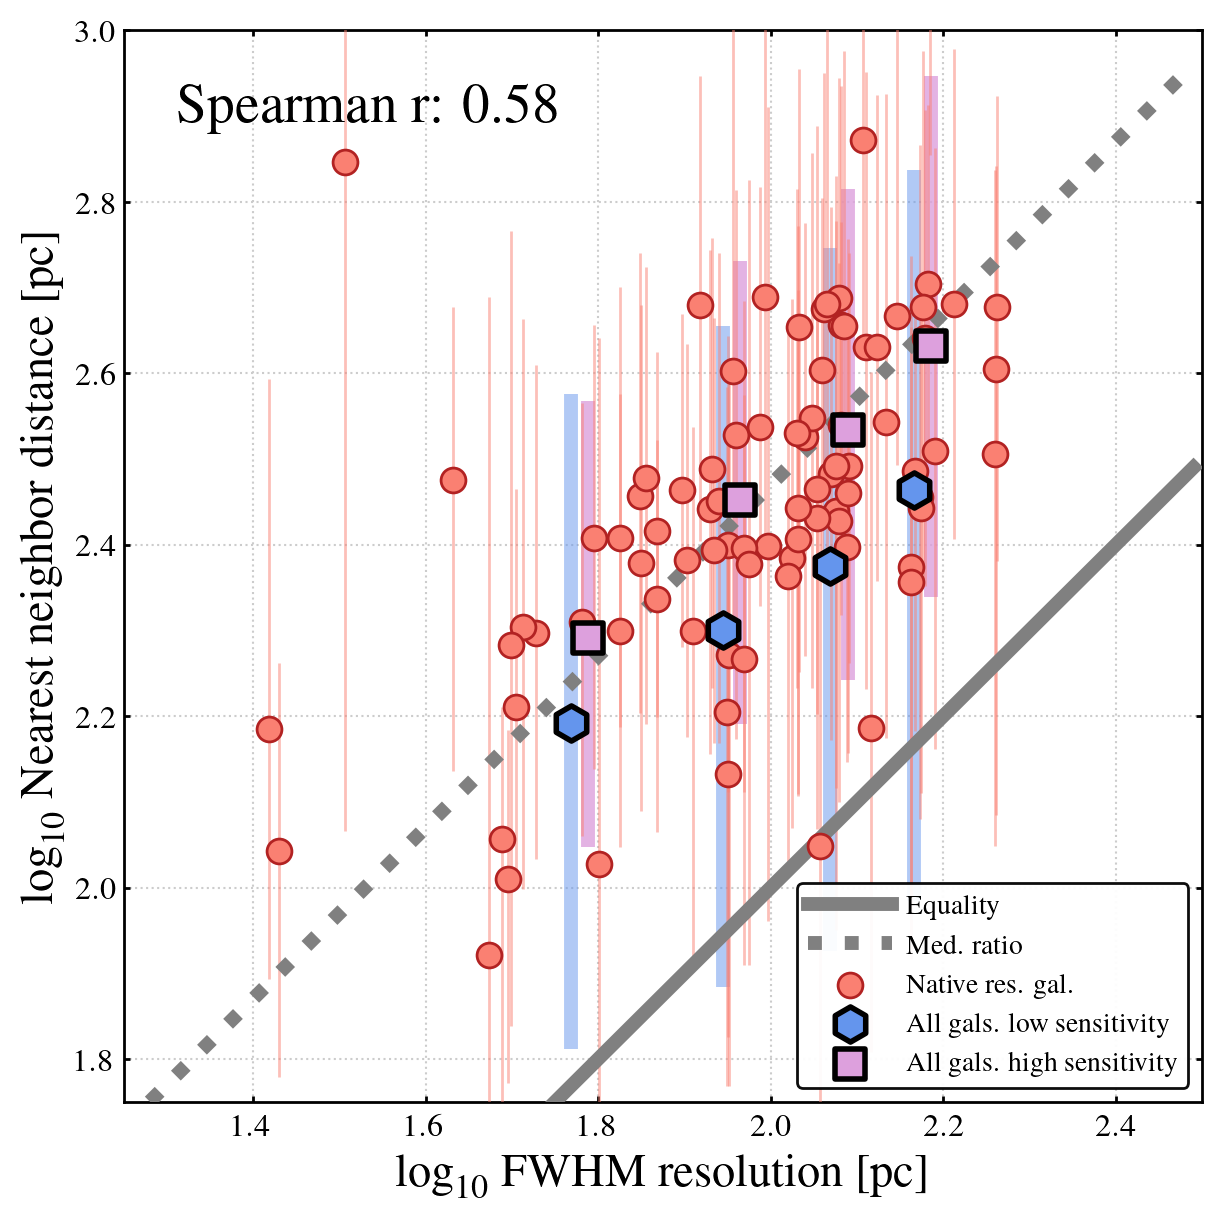

In [8]:
%matplotlib inline

png_name = '../plots/spacing_vs_res.png'

xmin = 1.25
xmax = 2.5
ymin = 1.75
ymax = 3.0
#xticks = [-1.0,-0.5,0.,0.5,1.,1.5,2.]
#yticks = [-0.5,-0.375,-0.25,-0.125,0.0]

mpl_setup('paper-1/1', aspect=6./6., fs=14)

fig, axes = plt.subplots(
    1, 1, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})

xlabel = r'$\log_{10}$ FWHM resolution [pc]'
ylabel = r'$\log_{10}$ Nearest neighbor distance [pc]'

rows_done = 0
counter = 0

axes.set_xlim([xmin,xmax])
axes.set_xscale('linear')
axes.set_ylim([ymin,ymax])
#axes.set_xticks(xticks)
#axes.set_yticks(yticks)
axes.set_xlabel(xlabel)    
axes.set_ylabel(ylabel)    

axes.hlines(
    axes.get_yticks(), axes.get_xlim()[0], axes.get_xlim()[1],        
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)
    
axes.vlines(
    axes.get_xticks(), axes.get_ylim()[0], axes.get_ylim()[1],
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)

fidx = np.arange(xmin,xmax,0.01)
axes.plot(fidx,fidx,zorder=3,color='gray',linewidth=5,label=r'Equality')
axes.plot(fidx,fidx+0.47,zorder=3,color='gray',linestyle='dotted',linewidth=5,label=r'Med. ratio')

#ind = (native_vec == 1)
#noise = np.random.normal(size=np.sum(ind))*0.005
#x = np.log10(res_vec[ind])+noise
#y = np.log10(spacing_vec[ind])
#z = np.log10(calc_local_density(x,y,support=(0.025,0.025)))
#axes.scatter(x, y,
#             marker='o', s=10, c=z, cmap='gray', edgecolor='gray',linewidth=0.25,
#             label=r'Individ. peaks (color shows density)', zorder=2)

first_native = True
for this_key in spacing_dict.keys():    
    this_spacing_dict = spacing_dict[this_key]
    if this_spacing_dict['IS_NATIVE'] == False:
        continue
    this_x = np.log10(this_spacing_dict['MED_RES_PC'])
    this_y = np.log10(this_spacing_dict['50'])
    this_lo = np.log10(this_spacing_dict['16'])
    this_hi = np.log10(this_spacing_dict['84'])
    
    if first_native:
        first_native = False
        label = r'Native res. gal.'
    else:
        label = None
    axes.scatter(this_x, this_y,
                marker='o', s=80, facecolor='salmon', edgecolor='firebrick', zorder=4,
                label=label)
    axes.errorbar(this_x, this_y, [[this_y-this_lo],[this_hi-this_y]],
                marker='.', color='salmon', ecolor='salmon', zorder=3, capsize=0, alpha=0.5)

first_fullcat = True
shift = -0.01
for this_key in spacing_dict.keys():    
    this_spacing_dict = spacing_dict[this_key]
    if this_spacing_dict['IS_HIGHNOISE'] == False:
        continue
    this_x = np.log10(this_spacing_dict['MED_RES_PC'])
    this_y = np.log10(this_spacing_dict['50'])
    this_lo = np.log10(this_spacing_dict['16'])
    this_hi = np.log10(this_spacing_dict['84'])
    
    if first_fullcat:
        first_fullcat = False
        label = r'All gals. low sensitivity'
    else:
        label = None    
    axes.scatter(this_x+shift, this_y,
                marker='h', s=160, facecolor='cornflowerblue', edgecolor='black', zorder=6,
                label=label, linewidth=2)
    axes.errorbar(this_x+shift, this_y, [[this_y-this_lo],[this_hi-this_y]],
                  marker='.', color='cornflowerblue', ecolor='cornflowerblue', 
                  zorder=1, capsize=0, elinewidth=5,alpha=0.5)
    
first_fullcat = True
shift = +0.01
for this_key in spacing_dict.keys():    
    this_spacing_dict = spacing_dict[this_key]
    if this_spacing_dict['IS_LOWNOISE'] == False:
        continue
    this_x = np.log10(this_spacing_dict['MED_RES_PC'])
    this_y = np.log10(this_spacing_dict['50'])
    this_lo = np.log10(this_spacing_dict['16'])
    this_hi = np.log10(this_spacing_dict['84'])
    
    if first_fullcat:
        first_fullcat = False
        label = r'All gals. high sensitivity'
    else:
        label = None
            
    axes.scatter(this_x+shift, this_y,
                marker='s', s=120, facecolor='plum', edgecolor='black', zorder=6,
                label=label, linewidth=2)
    axes.errorbar(this_x+shift, this_y, [[this_y-this_lo],[this_hi-this_y]],
                  marker='.', color='plum', ecolor='plum', 
                  zorder=0, capsize=0, elinewidth=5, alpha=0.8)
    
axes.legend(fancybox=True, framealpha=0.95, loc='lower right', 
            ncol=1, fontsize=10, handlelength=3)    

axes.tick_params(axis='both', which='major', length=2)
axes.tick_params(axis='both', which='minor', length=2)

# label the pearson coefficient
axes.annotate('Spearman r: 0.58', (0.05, 0.95), xycoords='axes fraction', ha='left', va='top', fontsize=20)

#fig.tight_layout()
plt.savefig(png_name, bbox_inches='tight')

Modify the same figure to one column figure

/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/matplotlib/axes/_base.py:2283: UserWarning: Warning: converting a masked element to nan.
  xys = np.asarray(xys)


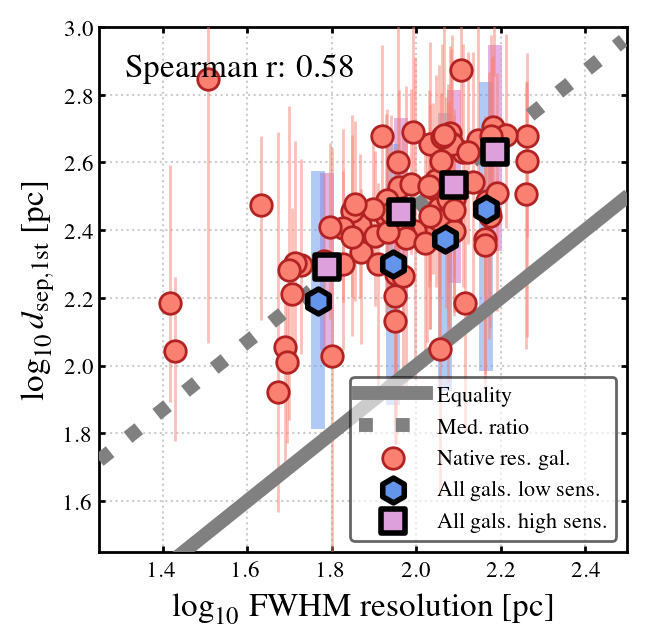

In [9]:
%matplotlib inline

png_name = '../plots/spacing_vs_res_onecol.png'

xmin = 1.25
xmax = 2.5
ymin = 1.45
ymax = 3.0
#xticks = [-1.0,-0.5,0.,0.5,1.,1.5,2.]
#yticks = [-0.5,-0.375,-0.25,-0.125,0.0]

mpl_setup('paper-1/2', aspect=6./6., fs=10)

fig, axes = plt.subplots(
    1, 1, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})

xlabel = r'$\log_{10}$ FWHM resolution [pc]'
ylabel = r'$\log_{10} d_{\mathrm{sep, 1st}}$ [pc]'

rows_done = 0
counter = 0

axes.set_xlim([xmin,xmax])
axes.set_xscale('linear')
axes.set_ylim([ymin,ymax])
#axes.set_xticks(xticks)
#axes.set_yticks(yticks)
axes.set_xlabel(xlabel)    
axes.set_ylabel(ylabel)    

axes.hlines(
    axes.get_yticks(), axes.get_xlim()[0], axes.get_xlim()[1],        
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)
    
axes.vlines(
    axes.get_xticks(), axes.get_ylim()[0], axes.get_ylim()[1],
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)

fidx = np.arange(xmin,xmax,0.01)
axes.plot(fidx,fidx,zorder=3,color='gray',linewidth=5,label=r'Equality')
axes.plot(fidx,fidx+0.47,zorder=3,color='gray',linestyle='dotted',linewidth=5,label=r'Med. ratio')

#ind = (native_vec == 1)
#noise = np.random.normal(size=np.sum(ind))*0.005
#x = np.log10(res_vec[ind])+noise
#y = np.log10(spacing_vec[ind])
#z = np.log10(calc_local_density(x,y,support=(0.025,0.025)))
#axes.scatter(x, y,
#             marker='o', s=10, c=z, cmap='gray', edgecolor='gray',linewidth=0.25,
#             label=r'Individ. peaks (color shows density)', zorder=2)

first_native = True
for this_key in spacing_dict.keys():    
    this_spacing_dict = spacing_dict[this_key]
    if this_spacing_dict['IS_NATIVE'] == False:
        continue
    this_x = np.log10(this_spacing_dict['MED_RES_PC'])
    this_y = np.log10(this_spacing_dict['50'])
    this_lo = np.log10(this_spacing_dict['16'])
    this_hi = np.log10(this_spacing_dict['84'])
    
    if first_native:
        first_native = False
        label = r'Native res. gal.'
    else:
        label = None
    axes.scatter(this_x, this_y,
                marker='o', s=60, facecolor='salmon', edgecolor='firebrick', zorder=4,
                label=label)
    axes.errorbar(this_x, this_y, [[this_y-this_lo],[this_hi-this_y]],
                marker='.', color='salmon', ecolor='salmon', zorder=3, capsize=0, alpha=0.5)

first_fullcat = True
shift = -0.01
for this_key in spacing_dict.keys():    
    this_spacing_dict = spacing_dict[this_key]
    if this_spacing_dict['IS_HIGHNOISE'] == False:
        continue
    this_x = np.log10(this_spacing_dict['MED_RES_PC'])
    this_y = np.log10(this_spacing_dict['50'])
    this_lo = np.log10(this_spacing_dict['16'])
    this_hi = np.log10(this_spacing_dict['84'])
    
    if first_fullcat:
        first_fullcat = False
        label = r'All gals. low sens.'
    else:
        label = None    
    axes.scatter(this_x+shift, this_y,
                marker='h', s=80, facecolor='cornflowerblue', edgecolor='black', zorder=6,
                label=label, linewidth=2)
    axes.errorbar(this_x+shift, this_y, [[this_y-this_lo],[this_hi-this_y]],
                  marker='.', color='cornflowerblue', ecolor='cornflowerblue', 
                  zorder=1, capsize=0, elinewidth=5,alpha=0.5)
    
first_fullcat = True
shift = +0.01
for this_key in spacing_dict.keys():    
    this_spacing_dict = spacing_dict[this_key]
    if this_spacing_dict['IS_LOWNOISE'] == False:
        continue
    this_x = np.log10(this_spacing_dict['MED_RES_PC'])
    this_y = np.log10(this_spacing_dict['50'])
    this_lo = np.log10(this_spacing_dict['16'])
    this_hi = np.log10(this_spacing_dict['84'])
    
    if first_fullcat:
        first_fullcat = False
        label = r'All gals. high sens.'
    else:
        label = None
            
    axes.scatter(this_x+shift, this_y,
                marker='s', s=80, facecolor='plum', edgecolor='black', zorder=6,
                label=label, linewidth=2)
    axes.errorbar(this_x+shift, this_y, [[this_y-this_lo],[this_hi-this_y]],
                  marker='.', color='plum', ecolor='plum', 
                  zorder=0, capsize=0, elinewidth=5, alpha=0.8)
    
axes.legend(fancybox=True, framealpha=0.6, loc='lower right', 
            ncol=1, fontsize=8, handlelength=3)    

axes.tick_params(axis='both', which='major', length=2)
axes.tick_params(axis='both', which='minor', length=2)

# label the pearson coefficient
axes.annotate('Spearman r: 0.58', (0.05, 0.95), xycoords='axes fraction', ha='left', va='top', fontsize=12, zorder=5)

#fig.tight_layout()
plt.savefig(png_name, bbox_inches='tight')

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/1302567454.py:63: RuntimeWarning: divide by zero encountered in log10
  ybins = bin_data(np.log10(x_vec), y_vec, xlo=xlo, xhi=xhi)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/1302567454.py:63: RuntimeWarning: invalid value encountered in log10
  ybins = bin_data(np.log10(x_vec), y_vec, xlo=xlo, xhi=xhi)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/1302567454.py:64: RuntimeWarning: divide by zero encountered in log10
  zbins = bin_data(np.log10(x_vec), z_vec, xlo=xlo, xhi=xhi)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/1302567454.py:64: RuntimeWarning: invalid value encountered in log10
  zbins = bin_data(np.log10(x_vec), z_vec, xlo=xlo, xhi=xhi)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/1302567454.py:66: RuntimeWarning: divide by zero encountered in log10
  axes.scatter(np.log10(x_vec), np.log10(y_vec), marker='o', s=5
/var/folders/k_/39

-0.3320820885872003 3.307960538970655e-229


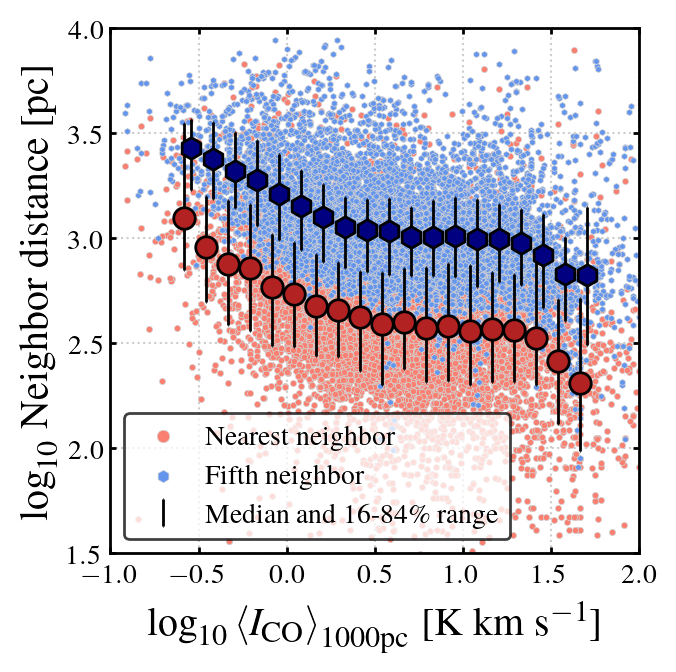

In [10]:
png_name = '../plots/dist_vs_ico.png'

xmin = -1.
xmax = 2.
ymin = 1.5
ymax = 4.0

mpl_setup('paper-1/2', aspect=10./10., fs=12)

fig, axes = plt.subplots(
    1, 1, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})

xlabel = r'$\log_{10} \left< I_{\rm CO} \right>_{\rm 1000 pc}$ [K km s$^{-1}$]'
ylabel = r'$\log_{10}$ Neighbor distance [pc]'

rows_done = 0
counter = 0

axes.set_xlim([xmin,xmax])
axes.set_xscale('linear')
axes.set_ylim([ymin,ymax])
#axes.set_xticks(xticks)
#axes.set_yticks(yticks)
axes.set_xlabel(xlabel)    
axes.set_ylabel(ylabel)    

axes.hlines(
    axes.get_yticks(), axes.get_xlim()[0], axes.get_xlim()[1],        
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)
    
axes.vlines(
    axes.get_xticks(), axes.get_ylim()[0], axes.get_ylim()[1],
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)

fidx = np.arange(xmin,xmax,0.01)
#axes.plot(fidx,fidx,zorder=3,color='gray',linewidth=5,label=r'Equality')
#axes.plot(fidx,fidx+0.47,zorder=3,color='gray',linestyle='dotted',linewidth=5,label=r'Med. ratio')

x_list = []
ex_list = []
y_list = []
z_list = []

for this_source in source_list:
    this_tab = fid_cat_tabs[this_source]
    this_x = np.array(this_tab['ICO21_1KPC'])
    this_ex = np.array(this_tab['EICO21_1KPC'])
    this_y = np.array(this_tab['DIST_NN1_PC'])
    this_z = np.array(this_tab['DIST_NN5_PC'])
    x_list.append(this_x)
    ex_list.append(this_ex)
    y_list.append(this_y)
    z_list.append(this_z)
    
x_vec = np.concatenate(x_list)
y_vec = np.concatenate(y_list)
z_vec = np.concatenate(z_list)

xlo, xhi, xmid, nbin = \
    make_spanning_bins(-0.625,1.8,0.125)

ybins = bin_data(np.log10(x_vec), y_vec, xlo=xlo, xhi=xhi)
zbins = bin_data(np.log10(x_vec), z_vec, xlo=xlo, xhi=xhi)

axes.scatter(np.log10(x_vec), np.log10(y_vec), marker='o', s=5
             ,facecolor='salmon',edgecolor='lightgray', zorder=1
             ,linewidth=0.25,label=r'Nearest neighbor')

axes.scatter(np.log10(x_vec), np.log10(z_vec), marker='h', s=5
             ,facecolor='cornflowerblue',edgecolor='lightgray', zorder=2
             ,linewidth=0.25,label=r'Fifth neighbor')

shift = 0.02
axes.scatter(ybins['xmid']-shift, np.log10(ybins['50']), marker='o', s=60
             , facecolor='firebrick', edgecolor='black'
             , zorder=5)
axes.errorbar(ybins['xmid']-shift, np.log10(ybins['50']),
                [np.log10(ybins['84'])-np.log10(ybins['50']),
                 np.log10(ybins['50'])-np.log10(ybins['16'])],
              color='black', capsize=0.1, elinewidth=1, fmt='none',
              marker='o',ms=10,
              zorder=3,label=r'Median and 16-84\% range')

axes.scatter(zbins['xmid']+shift, np.log10(zbins['50']), marker='h', s=60
             , facecolor='navy', edgecolor='black'
             , zorder=6)
axes.errorbar(zbins['xmid']+shift, np.log10(zbins['50']),
                [np.log10(zbins['84'])-np.log10(zbins['50']),
                 np.log10(zbins['50'])-np.log10(zbins['16'])],
              color='black', capsize=0.1, elinewidth=1, fmt='none',
              zorder=4)

legend = axes.legend(fancybox=True, framealpha=0.75, loc='lower left', 
            ncol=1, fontsize=10, handlelength=2, markerscale=2)    

axes.tick_params(axis='both', which='major', length=2)
axes.tick_params(axis='both', which='minor', length=2)

#fig.tight_layout()
plt.savefig(png_name, bbox_inches='tight')

# calculate the correlation coefficient and p-values
from scipy.stats import spearmanr
mask = (np.isnan(x_vec)) | (np.isnan(y_vec))
coeff, p = spearmanr(x_vec[~mask], y_vec[~mask])
print(coeff, p)

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/2713659314.py:64: RuntimeWarning: divide by zero encountered in log10
  ybins = bin_data(np.log10(x_vec), y_vec, xlo=xlo, xhi=xhi)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/2713659314.py:64: RuntimeWarning: invalid value encountered in log10
  ybins = bin_data(np.log10(x_vec), y_vec, xlo=xlo, xhi=xhi)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/2713659314.py:65: RuntimeWarning: divide by zero encountered in log10
  zbins = bin_data(np.log10(x_vec), z_vec, xlo=xlo, xhi=xhi)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/2713659314.py:65: RuntimeWarning: invalid value encountered in log10
  zbins = bin_data(np.log10(x_vec), z_vec, xlo=xlo, xhi=xhi)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/2713659314.py:68: RuntimeWarning: divide by zero encountered in log10
  axes.scatter(np.log10(x_vec), (y_vec+y_noise), marker='o', s=5
/var/folders/k_/39

0.34668398568414993 4.324656188789106e-252


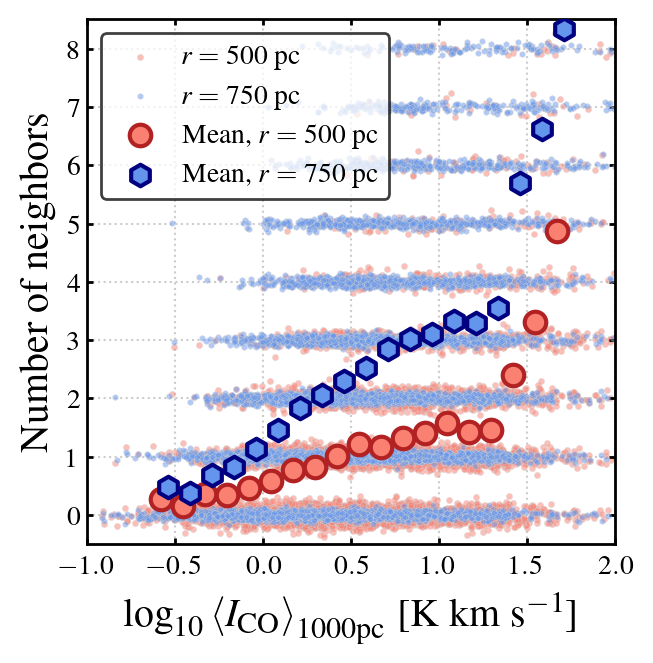

In [11]:
png_name = '../plots/nn_vs_ico.png'

xmin = -1.
xmax = 2.
ymin = -0.5
ymax = 8.5

mpl_setup('paper-1/2', aspect=6./6., fs=12)

fig, axes = plt.subplots(
    1, 1, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})

xlabel = r'$\log_{10} \left< I_{\rm CO} \right>_{\rm 1000 pc}$ [K km s$^{-1}$]'
ylabel = r'Number of neighbors'

rows_done = 0
counter = 0

axes.set_xlim([xmin,xmax])
axes.set_xscale('linear')
axes.set_ylim([ymin,ymax])
#axes.set_xticks(xticks)
#axes.set_yticks(yticks)
axes.set_xlabel(xlabel)    
axes.set_ylabel(ylabel)    

axes.hlines(
    axes.get_yticks(), axes.get_xlim()[0], axes.get_xlim()[1],        
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)
    
axes.vlines(
    axes.get_xticks(), axes.get_ylim()[0], axes.get_ylim()[1],
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)

fidx = np.arange(xmin,xmax,0.01)
#axes.plot(fidx,fidx,zorder=3,color='gray',linewidth=5,label=r'Equality')
#axes.plot(fidx,fidx+0.47,zorder=3,color='gray',linestyle='dotted',linewidth=5,label=r'Med. ratio')

x_list = []
ex_list = []
y_list = []
z_list = []

for this_source in source_list:
    this_tab = fid_cat_tabs[this_source]
    #print(this_source)
    this_x = np.array(this_tab['ICO21_1KPC'])
    this_ex = np.array(this_tab['EICO21_1KPC'])
    this_y = np.array(this_tab['NEIGHBORS_500PC'])
    this_z = np.array(this_tab['NEIGHBORS_750PC'])
    x_list.append(this_x)
    ex_list.append(this_ex)
    y_list.append(this_y)
    z_list.append(this_z)
    
x_vec = np.concatenate(x_list)
y_vec = np.concatenate(y_list)
z_vec = np.concatenate(z_list)

xlo, xhi, xmid, nbin = \
    make_spanning_bins(-0.625,1.8,0.125)

ybins = bin_data(np.log10(x_vec), y_vec, xlo=xlo, xhi=xhi)
zbins = bin_data(np.log10(x_vec), z_vec, xlo=xlo, xhi=xhi)

y_noise = y_vec*0. + np.random.normal(size=len(y_vec))*0.10
axes.scatter(np.log10(x_vec), (y_vec+y_noise), marker='o', s=5
             ,facecolor='salmon',edgecolor='lightgray', zorder=1
             ,linewidth=0.25,label=r'$r=500$~pc',alpha=0.5)

z_noise = z_vec*0. + np.random.normal(size=len(z_vec))*0.05
axes.scatter(np.log10(x_vec), (z_vec+z_noise), marker='h', s=5
             ,facecolor='cornflowerblue',edgecolor='lightgray', zorder=2
             ,linewidth=0.25,label=r'$r=750$~pc',alpha=0.5)

shift = 0.02
axes.scatter(ybins['xmid']-shift, (ybins['mean']), marker='o', s=60
             , facecolor='salmon', edgecolor='firebrick', linewidth=1.5
             , zorder=6, label=r'Mean, $r=500$~pc')
#axes.errorbar(ybins['xmid']-shift, (ybins['mean']), (ybins['stddev'])
#              , color='black', capsize=0.1, elinewidth=2, fmt='none'
#              , marker='o',s=10
#              , zorder=3,label=r'Median and std. dev.')

axes.scatter(zbins['xmid']+shift, (zbins['mean']), marker='h', s=60
             , facecolor='cornflowerblue', edgecolor='navy', linewidth=1.5
             , zorder=6, label=r'Mean, $r=750$~pc')
#axes.errorbar(zbins['xmid']+shift,(zbins['mean']),
#                [(zbins['84'])-(zbins['50']),
#                 (zbins['50'])-(zbins['16'])],
#              color='black', capsize=0.1, elinewidth=2, fmt='none',
#              zorder=4)

legend = axes.legend(fancybox=True, framealpha=0.75, loc='upper left', 
            ncol=1, fontsize=10, handlelength=2, markerscale=1)    

axes.tick_params(axis='both', which='major', length=2)
axes.tick_params(axis='both', which='minor', length=2)

#fig.tight_layout()
plt.savefig(png_name, bbox_inches='tight')

# calculate the correlation coefficient and p-values
from scipy.stats import spearmanr
mask = (np.isnan(x_vec)) | (np.isnan(y_vec))
coeff, p = spearmanr(x_vec[~mask], y_vec[~mask])
print(coeff, p)

Get the slope of number of neighbors versus Ico intensity

[0.41207024 0.35864171]
[0.17385626 0.44732875]
[ 0.79488391 -0.35832698]


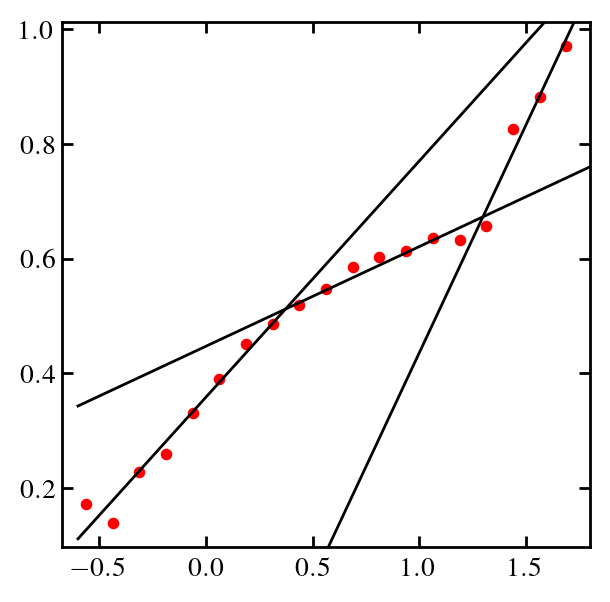

In [12]:
fig = plt.figure()
ax = plt.subplot(111)
plt.scatter(zbins['xmid'], np.log10(zbins['mean']+1), c='red', marker='o', s=10)
ax.set_xlim(); ax.set_ylim()
# fit the linear relation between number density and Ico kpc intensity
x = zbins['xmid'][:7]; y = np.log10(zbins['mean'][:7]+1)
coeff = np.polyfit(x, y, 1)
print(coeff)
xfit = np.arange(-0.6, 2.0, 0.1); yfit = coeff[0] * xfit + coeff[1]
plt.plot(xfit, yfit, color='black')
x = zbins['xmid'][7:15]; y = np.log10(zbins['mean'][7:15]+1)
coeff = np.polyfit(x, y, 1)
print(coeff)
xfit = np.arange(-0.6, 2.0, 0.1); yfit = coeff[0] * xfit + coeff[1]
plt.plot(xfit, yfit, color='black')
x = zbins['xmid'][15:]; y = np.log10(zbins['mean'][15:]+1)
coeff = np.polyfit(x, y, 1)
print(coeff)
xfit = np.arange(-0.6, 2.0, 0.1); yfit = coeff[0] * xfit + coeff[1]
plt.plot(xfit, yfit, color='black')


/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/1970468948.py:67: RuntimeWarning: divide by zero encountered in log10
  axes.scatter((x_vec), np.log10(y_vec), marker='o', s=5


0.23046111451918572 3.919060463200772e-108


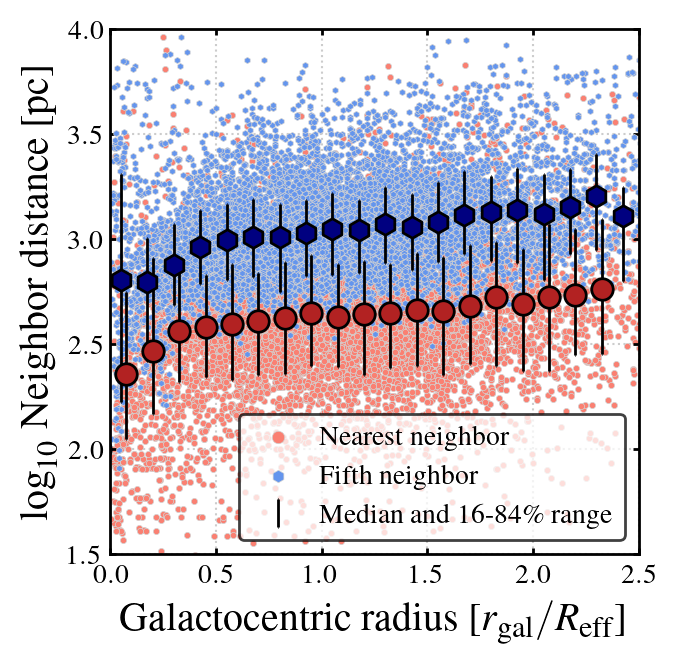

In [13]:
png_name = '../plots/dist_vs_rgal.png'

xmin = 0.0
xmax = 2.5
ymin = 1.5
ymax = 4.0

mpl_setup('paper-1/2', aspect=6./6., fs=12)

fig, axes = plt.subplots(
    1, 1, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})

xlabel = r'Galactocentric radius [$r_{\rm gal}/R_{\rm eff}$]'
ylabel = r'$\log_{10}$ Neighbor distance [pc]'

rows_done = 0
counter = 0

axes.set_xlim([xmin,xmax])
axes.set_xscale('linear')
axes.set_ylim([ymin,ymax])
#axes.set_xticks(xticks)
#axes.set_yticks(yticks)
axes.set_xlabel(xlabel)    
axes.set_ylabel(ylabel)    

axes.hlines(
    axes.get_yticks(), axes.get_xlim()[0], axes.get_xlim()[1],        
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)
    
axes.vlines(
    axes.get_xticks(), axes.get_ylim()[0], axes.get_ylim()[1],
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)

fidx = np.arange(xmin,xmax,0.01)
#axes.plot(fidx,fidx,zorder=3,color='gray',linewidth=5,label=r'Equality')
#axes.plot(fidx,fidx+0.47,zorder=3,color='gray',linestyle='dotted',linewidth=5,label=r'Med. ratio')

x_list = []
ex_list = []
y_list = []
z_list = []

for this_source in source_list:
    this_tab = fid_cat_tabs[this_source]
    deets = deets_dict[this_source]
    this_size = np.array(deets['size_reff'])        
    this_x = np.array(this_tab['RGAL_DEG'])*3600./this_size
    this_y = np.array(this_tab['DIST_NN1_PC'])
    this_z = np.array(this_tab['DIST_NN5_PC'])
    x_list.append(this_x)
    ex_list.append(this_ex)
    y_list.append(this_y)
    z_list.append(this_z)
    
x_vec = np.concatenate(x_list)
y_vec = np.concatenate(y_list)
z_vec = np.concatenate(z_list)

xlo, xhi, xmid, nbin = \
    make_spanning_bins(-0.0625,2.5,0.125)

ybins = bin_data((x_vec), y_vec, xlo=xlo, xhi=xhi)
zbins = bin_data((x_vec), z_vec, xlo=xlo, xhi=xhi)

axes.scatter((x_vec), np.log10(y_vec), marker='o', s=5
             ,facecolor='salmon',edgecolor='lightgray', zorder=1
             ,linewidth=0.25,label=r'Nearest neighbor')

shift = 0.05
axes.scatter(ybins['xmid']-shift, np.log10(ybins['50']), marker='o', s=60
             , facecolor='firebrick', edgecolor='black'
             , zorder=5)
axes.errorbar(ybins['xmid']-shift, np.log10(ybins['50']),
                [np.log10(ybins['84'])-np.log10(ybins['50']),
                 np.log10(ybins['50'])-np.log10(ybins['16'])],
              color='black', capsize=0.1, elinewidth=1, fmt='none',
              marker='o',ms=10,
              zorder=3,label=r'Median and 16-84\% range')

axes.scatter(zbins['xmid']+shift, np.log10(zbins['50']), marker='h', s=60
             , facecolor='navy', edgecolor='black'
             , zorder=6)
axes.errorbar(zbins['xmid']+shift, np.log10(zbins['50']),
                [np.log10(zbins['84'])-np.log10(zbins['50']),
                 np.log10(zbins['50'])-np.log10(zbins['16'])],
              color='black', capsize=0.1, elinewidth=1, fmt='none',
              zorder=4)

axes.scatter((x_vec), np.log10(z_vec), marker='h', s=5
             ,facecolor='cornflowerblue',edgecolor='lightgray', zorder=2
             ,linewidth=0.25,label=r'Fifth neighbor')

legend = axes.legend(fancybox=True, framealpha=0.75, loc='lower right', 
            ncol=1, fontsize=10, handlelength=2, markerscale=2)    

axes.tick_params(axis='both', which='major', length=2)
axes.tick_params(axis='both', which='minor', length=2)

#fig.tight_layout()
plt.savefig(png_name, bbox_inches='tight')

# calculate the correlation coefficient and p-values
from scipy.stats import spearmanr
mask = (np.isnan(x_vec)) | (np.isnan(y_vec))
coeff, p = spearmanr(x_vec[~mask], y_vec[~mask])
print(coeff, p)

-0.2510276526000917 3.769884171572691e-129


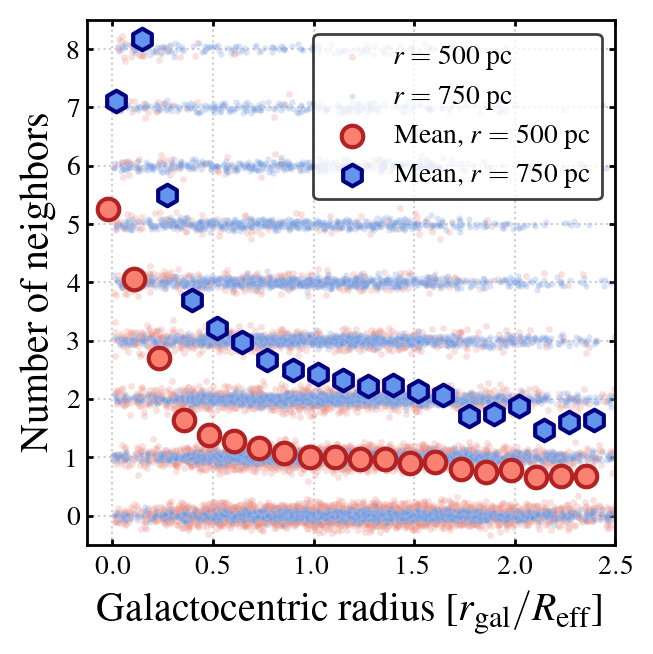

In [15]:
%matplotlib inline

png_name = '../plots/nn_vs_rgal.png'

xmin = -0.125
xmax = 2.5
ymin = -0.5
ymax = 8.5

# some format change from Hao He
aspect = 4./6
fs = 10 
s = 60
linewidth = 2
labelsize = 8


mpl_setup('paper-1/2', aspect=3./3., fs=12)

fig, axes = plt.subplots(
    1, 1, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})

xlabel = r'Galactocentric radius [$r_{\rm gal}/R_{\rm eff}$]'
ylabel = r'Number of neighbors'

rows_done = 0
counter = 0

axes.set_xlim([xmin,xmax])
axes.set_xscale('linear')
axes.set_ylim([ymin,ymax])
#axes.set_xticks(xticks)
#axes.set_yticks(yticks)
axes.set_xlabel(xlabel)    
axes.set_ylabel(ylabel)    

axes.hlines(
    axes.get_yticks(), axes.get_xlim()[0], axes.get_xlim()[1],        
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)
    
axes.vlines(
    axes.get_xticks(), axes.get_ylim()[0], axes.get_ylim()[1],
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)

fidx = np.arange(xmin,xmax,0.01)
#axes.plot(fidx,fidx,zorder=3,color='gray',linewidth=5,label=r'Equality')
#axes.plot(fidx,fidx+0.47,zorder=3,color='gray',linestyle='dotted',linewidth=5,label=r'Med. ratio')

x_list = []
y_list = []
z_list = []

for this_source in source_list:
    this_tab = fid_cat_tabs[this_source]
    deets = deets_dict[this_source]
    this_size = np.array(deets['size_reff'])        
    this_x = np.array(this_tab['RGAL_DEG'])*3600./this_size
    this_y = np.array(this_tab['NEIGHBORS_500PC'])
    this_z = np.array(this_tab['NEIGHBORS_750PC'])
    x_list.append(this_x)
    y_list.append(this_y)
    z_list.append(this_z)
    
x_vec = np.concatenate(x_list)
y_vec = np.concatenate(y_list)
z_vec = np.concatenate(z_list)

xlo, xhi, xmid, nbin = \
    make_spanning_bins(-0.0625,2.5,0.125)

ybins = bin_data((x_vec), y_vec, xlo=xlo, xhi=xhi)
zbins = bin_data((x_vec), z_vec, xlo=xlo, xhi=xhi)

y_noise = y_vec*0. + np.random.normal(size=len(y_vec))*0.10
axes.scatter((x_vec), (y_vec+y_noise), marker='o', s=5
             ,facecolor='salmon',edgecolor='lightgray', zorder=1
             ,linewidth=0.25,label=r'$r=500$~pc',alpha=0.25)

z_noise = z_vec*0. + np.random.normal(size=len(z_vec))*0.05
axes.scatter((x_vec), (z_vec+z_noise), marker='h', s=5
             ,facecolor='cornflowerblue',edgecolor='lightgray', zorder=2
             ,linewidth=0.25,label=r'$r=750$~pc',alpha=0.25)

shift = 0.02
axes.scatter(ybins['xmid']-shift, (ybins['mean']), marker='o', s=60
             , facecolor='salmon', edgecolor='firebrick', linewidth=1.5
             , zorder=5, label=r'Mean, $r=500$~pc')
#axes.errorbar(ybins['xmid']-shift, (ybins['mean']), (ybins['stddev'])
#              , color='black', capsize=0.1, elinewidth=2, fmt='none'
#              , marker='o',s=10
#              , zorder=3,label=r'Median and std. dev.')

axes.scatter(zbins['xmid']+shift, (zbins['mean']), marker='h', s=60
             , facecolor='cornflowerblue', edgecolor='navy', linewidth=1.5
             , zorder=6, label=r'Mean, $r=750$~pc')
#axes.errorbar(zbins['xmid']+shift,(zbins['mean']),
#                [(zbins['84'])-(zbins['50']),
#                 (zbins['50'])-(zbins['16'])],
#              color='black', capsize=0.1, elinewidth=2, fmt='none',
#              zorder=4)

legend = axes.legend(fancybox=True, framealpha=0.75, loc='upper right', 
            ncol=1, fontsize=10, handlelength=2, markerscale=1)    

axes.tick_params(axis='both', which='major', length=2)
axes.tick_params(axis='both', which='minor', length=2)

#fig.tight_layout()
plt.savefig(png_name, bbox_inches='tight')

# calculate the correlation coefficient and p-values
from scipy.stats import spearmanr
mask = (np.isnan(x_vec)) | (np.isnan(y_vec))
coeff, p = spearmanr(x_vec[~mask], y_vec[~mask])
print(coeff, p)

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/1372526805.py:68: RuntimeWarning: divide by zero encountered in log10
  axes.scatter((x_vec), np.log10(y_vec), marker='o', s=5
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/1372526805.py:68: RuntimeWarning: invalid value encountered in log10
  axes.scatter((x_vec), np.log10(y_vec), marker='o', s=5
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/1372526805.py:72: RuntimeWarning: divide by zero encountered in log10
  axes.scatter((x_vec), np.log10(z_vec), marker='h', s=5
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/1372526805.py:72: RuntimeWarning: invalid value encountered in log10
  axes.scatter((x_vec), np.log10(z_vec), marker='h', s=5


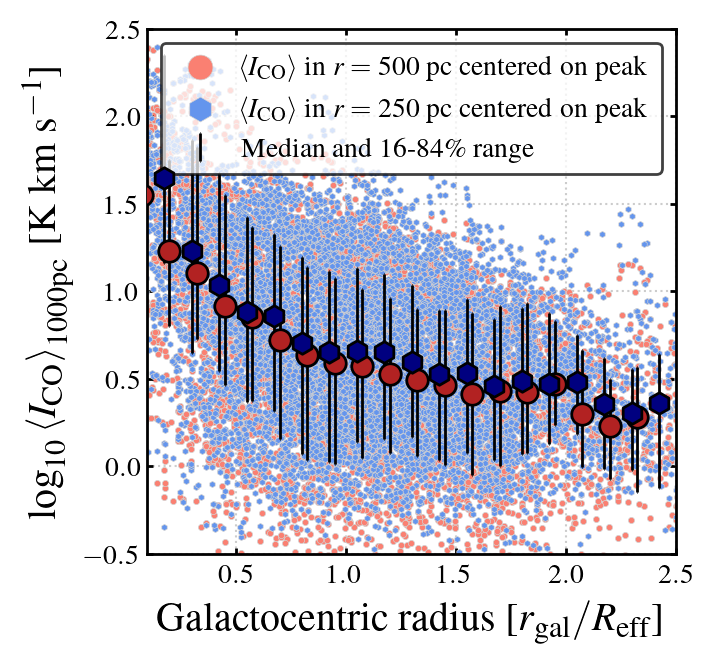

In [16]:
%matplotlib inline

png_name = '../plots/ico_vs_rgal.png'

xmin = 0.1
xmax = 2.5
ymin = -0.5
ymax = 2.5

mpl_setup('paper-1/2', aspect=6./6., fs=12)

fig, axes = plt.subplots(
    1, 1, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})


xlabel = r'Galactocentric radius [$r_{\rm gal}/R_{\rm eff}$]'
ylabel = r'$\log_{10} \left< I_{\rm CO} \right>_{\rm 1000 pc}$ [K km s$^{-1}$]'

rows_done = 0
counter = 0

axes.set_xlim([xmin,xmax])
axes.set_xscale('linear')
axes.set_ylim([ymin,ymax])
#axes.set_xticks(xticks)
#axes.set_yticks(yticks)
axes.set_xlabel(xlabel)    
axes.set_ylabel(ylabel)    

axes.hlines(
    axes.get_yticks(), axes.get_xlim()[0], axes.get_xlim()[1],        
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)
    
axes.vlines(
    axes.get_xticks(), axes.get_ylim()[0], axes.get_ylim()[1],
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)

fidx = np.arange(xmin,xmax,0.01)
#axes.plot(fidx,fidx,zorder=3,color='gray',linewidth=5,label=r'Equality')
#axes.plot(fidx,fidx+0.47,zorder=3,color='gray',linestyle='dotted',linewidth=5,label=r'Med. ratio')

x_list = []
y_list = []
z_list = []

for this_source in source_list:
    this_tab = fid_cat_tabs[this_source]
    deets = deets_dict[this_source]
    this_size = np.array(deets['size_reff'])        
    this_x = np.array(this_tab['RGAL_DEG'])*3600./this_size
    this_y = np.array(this_tab['ICO21_1KPC'])    
    this_z = np.array(this_tab['ICO21_500PC'])    
    x_list.append(this_x)
    y_list.append(this_y)
    z_list.append(this_z)
    
x_vec = np.concatenate(x_list)
y_vec = np.concatenate(y_list)
z_vec = np.concatenate(z_list)

xlo, xhi, xmid, nbin = \
    make_spanning_bins(-0.0625,2.5,0.125)

ybins = bin_data((x_vec), y_vec, xlo=xlo, xhi=xhi)
zbins = bin_data((x_vec), z_vec, xlo=xlo, xhi=xhi)

axes.scatter((x_vec), np.log10(y_vec), marker='o', s=5
             ,facecolor='salmon',edgecolor='lightgray', zorder=1
             ,linewidth=0.25,label=r'$\left<I_{\rm CO}\right>$ in $r=500$~pc centered on peak')

axes.scatter((x_vec), np.log10(z_vec), marker='h', s=5
             ,facecolor='cornflowerblue',edgecolor='lightgray', zorder=2
             ,linewidth=0.25,label=r'$\left<I_{\rm CO}\right>$ in $r=250$~pc centered on peak')

shift = 0.05
axes.scatter(ybins['xmid']-shift, np.log10(ybins['50']), marker='o', s=60
             , facecolor='firebrick', edgecolor='black'
             , zorder=5)
axes.errorbar(ybins['xmid']-shift, np.log10(ybins['50']),
                [np.log10(ybins['84'])-np.log10(ybins['50']),
                 np.log10(ybins['50'])-np.log10(ybins['16'])],
              color='black', capsize=0.1, elinewidth=1, fmt='none',
              marker='o',ms=10,
              zorder=3,label=r'Median and 16-84\% range')

axes.scatter(zbins['xmid']+shift, np.log10(zbins['50']), marker='h', s=60
             , facecolor='navy', edgecolor='black'
             , zorder=6)
axes.errorbar(zbins['xmid']+shift, np.log10(zbins['50']),
                [np.log10(zbins['84'])-np.log10(zbins['50']),
                 np.log10(zbins['50'])-np.log10(zbins['16'])],
              color='black', capsize=0.1, elinewidth=1, fmt='none',
              zorder=4)

legend = axes.legend(fancybox=True, framealpha=0.75, loc='upper right', 
            ncol=1, fontsize=10, handlelength=2, markerscale=4)    

axes.tick_params(axis='both', which='major', length=2)
axes.tick_params(axis='both', which='minor', length=2)

#fig.tight_layout()
plt.savefig(png_name, bbox_inches='tight')

Calculate the GMC number density using two metrics and compare it with the Ico vs rgal trend. 

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/1672262336.py:66: RuntimeWarning: divide by zero encountered in log10
  axes.scatter((x_vec), np.log10(y_vec), marker='o', s=5
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/1672262336.py:66: RuntimeWarning: invalid value encountered in log10
  axes.scatter((x_vec), np.log10(y_vec), marker='o', s=5
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/1672262336.py:70: RuntimeWarning: divide by zero encountered in log10
  axes.scatter((x_vec), np.log10(z_vec), marker='h', s=5
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/1672262336.py:70: RuntimeWarning: invalid value encountered in log10
  axes.scatter((x_vec), np.log10(z_vec), marker='h', s=5


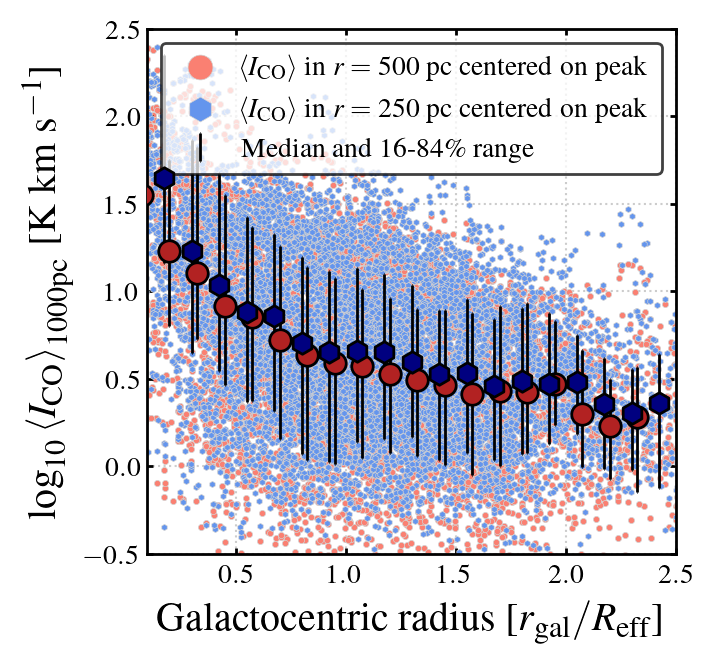

In [17]:


png_name = '../plots/density_vs_rgal.png'

xmin = 0.1
xmax = 2.5
ymin = -0.5
ymax = 2.5

mpl_setup('paper-1/2', aspect=6./6., fs=12)

fig, axes = plt.subplots(
    1, 1, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})


xlabel = r'Galactocentric radius [$r_{\rm gal}/R_{\rm eff}$]'
ylabel = r'$\log_{10} \left< I_{\rm CO} \right>_{\rm 1000 pc}$ [K km s$^{-1}$]'

rows_done = 0
counter = 0

axes.set_xlim([xmin,xmax])
axes.set_xscale('linear')
axes.set_ylim([ymin,ymax])
#axes.set_xticks(xticks)
#axes.set_yticks(yticks)
axes.set_xlabel(xlabel)    
axes.set_ylabel(ylabel)    

axes.hlines(
    axes.get_yticks(), axes.get_xlim()[0], axes.get_xlim()[1],        
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)
    
axes.vlines(
    axes.get_xticks(), axes.get_ylim()[0], axes.get_ylim()[1],
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)

fidx = np.arange(xmin,xmax,0.01)
#axes.plot(fidx,fidx,zorder=3,color='gray',linewidth=5,label=r'Equality')
#axes.plot(fidx,fidx+0.47,zorder=3,color='gray',linestyle='dotted',linewidth=5,label=r'Med. ratio')

x_list = []
y_list = []
z_list = []

for this_source in source_list:
    this_tab = fid_cat_tabs[this_source]
    deets = deets_dict[this_source]
    this_size = np.array(deets['size_reff'])        
    this_x = np.array(this_tab['RGAL_DEG'])*3600./this_size
    this_y = np.array(this_tab['ICO21_1KPC'])    
    this_z = np.array(this_tab['ICO21_500PC'])    
    x_list.append(this_x)
    y_list.append(this_y)
    z_list.append(this_z)
    
x_vec = np.concatenate(x_list)
y_vec = np.concatenate(y_list)
z_vec = np.concatenate(z_list)

xlo, xhi, xmid, nbin = \
    make_spanning_bins(-0.0625,2.5,0.125)

ybins = bin_data((x_vec), y_vec, xlo=xlo, xhi=xhi)
zbins = bin_data((x_vec), z_vec, xlo=xlo, xhi=xhi)

axes.scatter((x_vec), np.log10(y_vec), marker='o', s=5
             ,facecolor='salmon',edgecolor='lightgray', zorder=1
             ,linewidth=0.25,label=r'$\left<I_{\rm CO}\right>$ in $r=500$~pc centered on peak')

axes.scatter((x_vec), np.log10(z_vec), marker='h', s=5
             ,facecolor='cornflowerblue',edgecolor='lightgray', zorder=2
             ,linewidth=0.25,label=r'$\left<I_{\rm CO}\right>$ in $r=250$~pc centered on peak')

shift = 0.05
axes.scatter(ybins['xmid']-shift, np.log10(ybins['50']), marker='o', s=60
             , facecolor='firebrick', edgecolor='black'
             , zorder=5)
axes.errorbar(ybins['xmid']-shift, np.log10(ybins['50']),
                [np.log10(ybins['84'])-np.log10(ybins['50']),
                 np.log10(ybins['50'])-np.log10(ybins['16'])],
              color='black', capsize=0.1, elinewidth=1, fmt='none',
              marker='o',ms=10,
              zorder=3,label=r'Median and 16-84\% range')

axes.scatter(zbins['xmid']+shift, np.log10(zbins['50']), marker='h', s=60
             , facecolor='navy', edgecolor='black'
             , zorder=6)
axes.errorbar(zbins['xmid']+shift, np.log10(zbins['50']),
                [np.log10(zbins['84'])-np.log10(zbins['50']),
                 np.log10(zbins['50'])-np.log10(zbins['16'])],
              color='black', capsize=0.1, elinewidth=1, fmt='none',
              zorder=4)

legend = axes.legend(fancybox=True, framealpha=0.75, loc='upper right', 
            ncol=1, fontsize=10, handlelength=2, markerscale=4)    

axes.tick_params(axis='both', which='major', length=2)
axes.tick_params(axis='both', which='minor', length=2)

#fig.tight_layout()

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/3035922662.py:61: RuntimeWarning: divide by zero encountered in log10
  ybins = bin_data(np.log10(x_vec), y_vec, xlo=xlo, xhi=xhi)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/3035922662.py:62: RuntimeWarning: divide by zero encountered in log10
  zbins = bin_data(np.log10(x_vec), z_vec, xlo=xlo, xhi=xhi)
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/3035922662.py:65: RuntimeWarning: divide by zero encountered in log10
  axes.scatter(np.log10(x_vec), (y_vec+y_noise), marker='o', s=10
/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/3035922662.py:70: RuntimeWarning: divide by zero encountered in log10
  axes.scatter(np.log10(x_vec), (z_vec+z_noise), marker='h', s=10


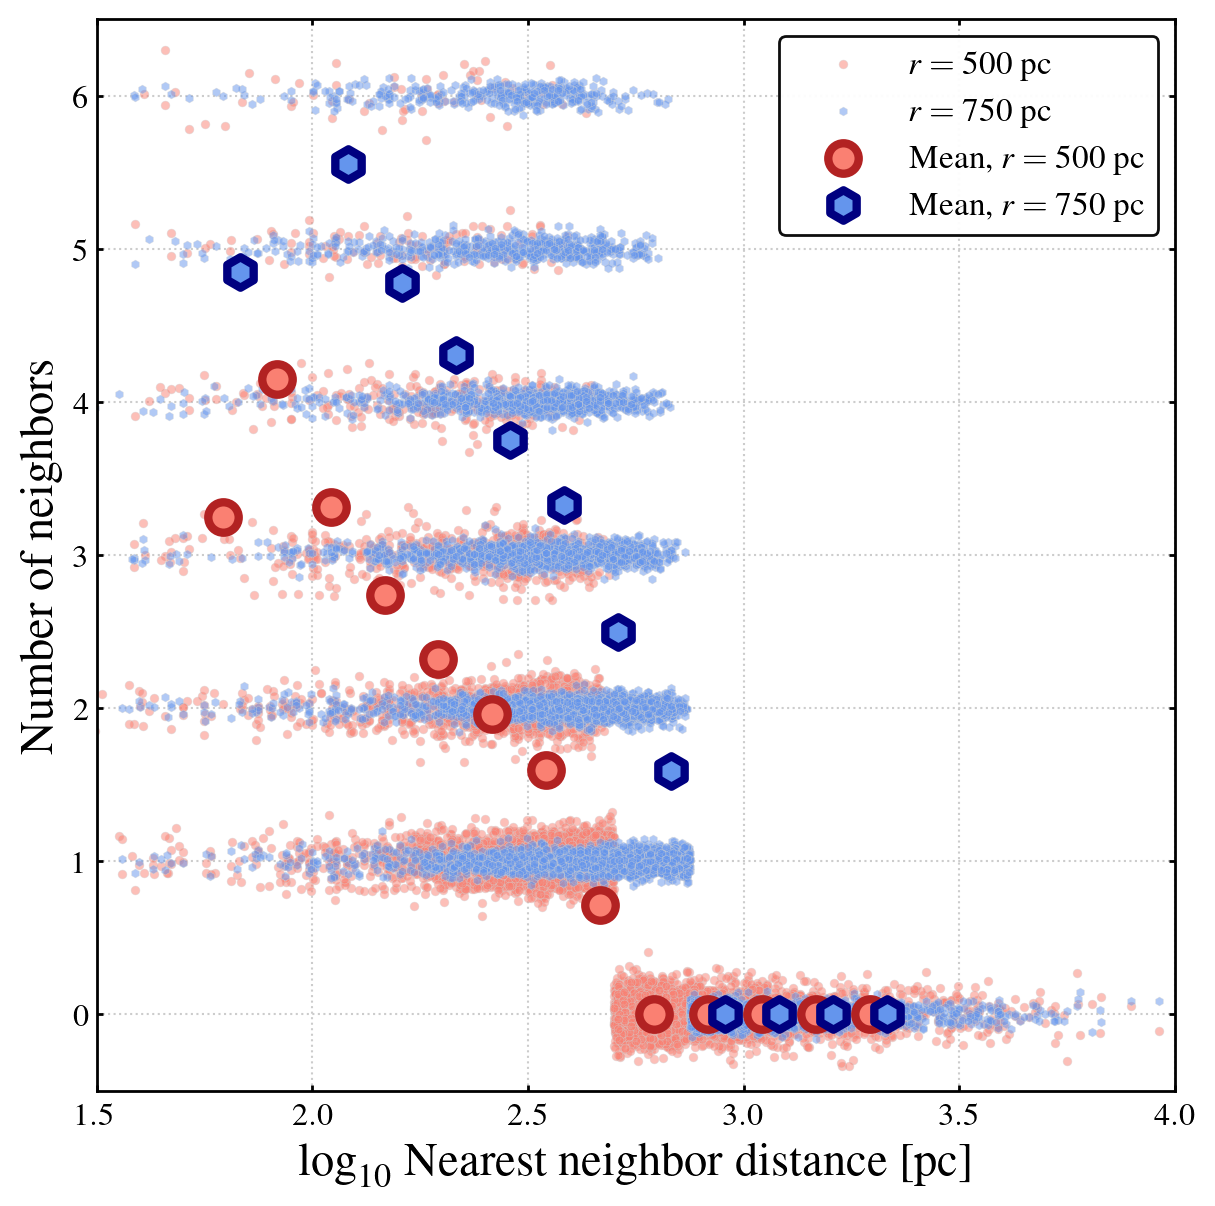

In [18]:
png_name = '../plots/nn_vs_dist.png'

xmin = 1.5
xmax = 4.
ymin = -0.5
ymax = 6.5

mpl_setup('paper-1/1', aspect=6./6., fs=14)

fig, axes = plt.subplots(
    1, 1, sharex='all', sharey='all',
    gridspec_kw={'wspace': 0.1, 'hspace': 0.1})

xlabel = r'$\log_{10}$ Nearest neighbor distance [pc]'
ylabel = r'Number of neighbors'

rows_done = 0
counter = 0

axes.set_xlim([xmin,xmax])
axes.set_xscale('linear')
axes.set_ylim([ymin,ymax])
#axes.set_xticks(xticks)
#axes.set_yticks(yticks)
axes.set_xlabel(xlabel)    
axes.set_ylabel(ylabel)    

axes.hlines(
    axes.get_yticks(), axes.get_xlim()[0], axes.get_xlim()[1],        
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)
    
axes.vlines(
    axes.get_xticks(), axes.get_ylim()[0], axes.get_ylim()[1],
    colors='0.8', linestyles='dotted', zorder=0, linewidth=0.75)

fidx = np.arange(xmin,xmax,0.01)
#axes.plot(fidx,fidx,zorder=3,color='gray',linewidth=5,label=r'Equality')
#axes.plot(fidx,fidx+0.47,zorder=3,color='gray',linestyle='dotted',linewidth=5,label=r'Med. ratio')

x_list = []
y_list = []
z_list = []

for this_source in source_list:
    this_tab = fid_cat_tabs[this_source]
    #print(this_source)
    this_x = np.array(this_tab['DIST_NN1_PC'])  
    this_y = np.array(this_tab['NEIGHBORS_500PC'])
    this_z = np.array(this_tab['NEIGHBORS_750PC'])
    x_list.append(this_x)    
    y_list.append(this_y)
    z_list.append(this_z)
    
x_vec = np.concatenate(x_list)
y_vec = np.concatenate(y_list)
z_vec = np.concatenate(z_list)

xlo, xhi, xmid, nbin = \
    make_spanning_bins(1.75,3.5,0.125)

ybins = bin_data(np.log10(x_vec), y_vec, xlo=xlo, xhi=xhi)
zbins = bin_data(np.log10(x_vec), z_vec, xlo=xlo, xhi=xhi)

y_noise = y_vec*0. + np.random.normal(size=len(y_vec))*0.10
axes.scatter(np.log10(x_vec), (y_vec+y_noise), marker='o', s=10
             ,facecolor='salmon',edgecolor='lightgray', zorder=1
             ,linewidth=0.25,label=r'$r=500$~pc',alpha=0.5)

z_noise = z_vec*0. + np.random.normal(size=len(z_vec))*0.05
axes.scatter(np.log10(x_vec), (z_vec+z_noise), marker='h', s=10
             ,facecolor='cornflowerblue',edgecolor='lightgray', zorder=2
             ,linewidth=0.25,label=r'$r=750$~pc',alpha=0.5)

shift = 0.02
axes.scatter(ybins['xmid']-shift, (ybins['mean']), marker='o', s=120
             , facecolor='salmon', edgecolor='firebrick', linewidth=3
             , zorder=6, label=r'Mean, $r=500$~pc')
#axes.errorbar(ybins['xmid']-shift, (ybins['mean']), (ybins['stddev'])
#              , color='black', capsize=0.1, elinewidth=2, fmt='none'
#              , marker='o',s=10
#              , zorder=3,label=r'Median and std. dev.')

axes.scatter(zbins['xmid']+shift, (zbins['mean']), marker='h', s=120
             , facecolor='cornflowerblue', edgecolor='navy', linewidth=3
             , zorder=6, label=r'Mean, $r=750$~pc')
#axes.errorbar(zbins['xmid']+shift,(zbins['mean']),
#                [(zbins['84'])-(zbins['50']),
#                 (zbins['50'])-(zbins['16'])],
#              color='black', capsize=0.1, elinewidth=2, fmt='none',
#              zorder=4)

legend = axes.legend(fancybox=True, framealpha=0.95, loc='upper right', 
            ncol=1, fontsize=12, handlelength=3, markerscale=1)    

axes.tick_params(axis='both', which='major', length=2)
axes.tick_params(axis='both', which='minor', length=2)

#fig.tight_layout()
plt.savefig(png_name, bbox_inches='tight')

Create a table that tabulates the values of medians of clustering metrics

In [19]:
columns = ['rgal', 'Ico_1kpc', 'd_sep', 'NN_500pc']
stats_med_tab = Table()

# stack the gmcs to have the 
gmc_stacked = Table()
for i, this_source in enumerate(source_list):
    this_tab = fid_cat_tabs[this_source]
    gmc_stacked = vstack([gmc_stacked, this_tab])
# join the GMC table with sample table     
gmc_sample_merged = join(gmc_stacked, sample_tab, join_type='left', keys_left='GALAXY', keys_right='name')
gmc_sample_merged['size_reff'] = gmc_sample_merged['RGAL_DEG'] * 3600 / gmc_sample_merged['size_reff']

# Bin the values by the normalized rgal.
xlo, xhi, xmid, nbin = \
    make_spanning_bins(-0.05,2.5,0.1)
Ico_1kpc_bins = bin_data(gmc_sample_merged['size_reff'], gmc_sample_merged['ICO21_1KPC'], xlo=xlo, xhi=xhi)
sep_bins = bin_data(gmc_sample_merged['size_reff'], gmc_sample_merged['DIST_NN1_PC'], xlo=xlo, xhi=xhi)
NN_bins = bin_data(gmc_sample_merged['size_reff'], gmc_sample_merged['NEIGHBORS_500PC'], xlo=xlo, xhi=xhi)

stats_med_tab['rgal'] = np.round(xmid, 1)
# stats_med_tab['Ico_1kpc'] = [f"${m:.1f}^{{+{u-m:.1f}}}_{{-{m-l:.1f}}}$" 
#                     for m, u, l in zip(np.log10(Ico_1kpc_bins['50']), np.log10(Ico_1kpc_bins['84']), np.log10(Ico_1kpc_bins['16']))]
# stats_med_tab['d_sep'] = [f"${m:.1f}^{{+{u-m:.1f}}}_{{-{m-l:.1f}}}$" 
#                     for m, u, l in zip(np.log10(sep_bins['50']), np.log10(sep_bins['84']), np.log10(sep_bins['16']))]
stats_med_tab['Ico_1kpc_med'] = np.round(np.log10(Ico_1kpc_bins['50']), 1)
stats_med_tab['Ico_1kpc_16th'] = np.round(np.log10(Ico_1kpc_bins['16']), 1)
stats_med_tab['Ico_1kpc_84th'] = np.round(np.log10(Ico_1kpc_bins['84']), 1)
stats_med_tab['d_sep_med'] = np.round(np.log10(sep_bins['50']), 1)
stats_med_tab['d_sep_16th'] = np.round(np.log10(sep_bins['16']), 1)
stats_med_tab['d_sep_84th'] = np.round(np.log10(sep_bins['84']), 1)
stats_med_tab['NN_500pc'] = NN_bins['mean']; stats_med_tab['NN_500pc'].format = '.1f'

display(stats_med_tab)
stats_med_tab.write('../tables/spacing_nn.tex', format='latex', overwrite=True)



/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4650: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  arr.partition(
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4650: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  arr.partition(
/Users/haohe/miniconda3/envs/research/lib/python3.8/site-packages/numpy/lib/function_base.py:4650: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  arr.partition(


rgal,Ico_1kpc_med,Ico_1kpc_16th,Ico_1kpc_84th,d_sep_med,d_sep_16th,d_sep_84th,NN_500pc
float64,float64,float64,float64,float64,float64,float64,float64
0.0,1.7,0.8,2.1,2.0,1.6,2.4,5.7
0.1,1.6,0.8,2.0,2.3,1.9,2.6,4.3
0.2,1.3,0.8,1.7,2.4,2.0,2.7,3.1
0.3,1.2,0.6,1.6,2.5,2.1,2.8,2.2
0.4,1.0,0.4,1.5,2.6,2.2,2.8,1.6
0.5,0.9,0.3,1.4,2.6,2.3,2.8,1.3
0.6,0.9,0.4,1.3,2.6,2.3,2.8,1.3
0.7,0.8,0.2,1.3,2.6,2.3,2.9,1.2
0.8,0.7,0.2,1.3,2.6,2.4,2.9,1.1


Compare the number density profiles from measurements with that predicted from Ico,1kpc

In [20]:
from scipy.interpolate import interp1d

# read the phangs sample
sample_tab =  Table.read('../phangs_sample_table_v1p6.fits')

# define bins for radius
xlo, xhi, xmid, nbin = \
    make_spanning_bins(-0.05,2.0,0.1)
bins = np.append(0, xhi)

Ico_rad_arr = np.zeros((len(source_list), len(xmid)))

# for each galaxy, calculate the number density using different methods
for i, source in enumerate(source_list):
    this_row = sample_tab[sample_tab['name']==source]
    this_dist = this_row['dist'] # in Mpc
    this_lstar_kpc = 4.85 * this_dist * this_row['size_scalelength']  / 1000
    
    
    # Ico radial profile
    radial_profile_table = Table.read('../radial_profiles/'
            +source.upper()+'_base_annulus_0p5kpc.ecsv')
    radial_dist_kpc = radial_profile_table['r_gal'] 
    radial_dist_reff = radial_dist_kpc / this_lstar_kpc
    Ico_rad = radial_profile_table['I_CO21']
    radial_profile_func = interp1d(radial_dist_reff, Ico_rad, fill_value='extrapolate')
    Ico_rad_regrid = radial_profile_func(xmid)
    Ico_rad_arr[i] = Ico_rad_regrid
    
Ico_rad_mean = np.nanmean(Ico_rad_arr, axis=0)

/var/folders/k_/39d0867x0lzfs4tlp5yndtg40000gn/T/ipykernel_52559/12604600.py:5: RuntimeWarning: divide by zero encountered in true_divide
  nn_from_counts = counts / math.pi / (xhi**2-xlo**2)


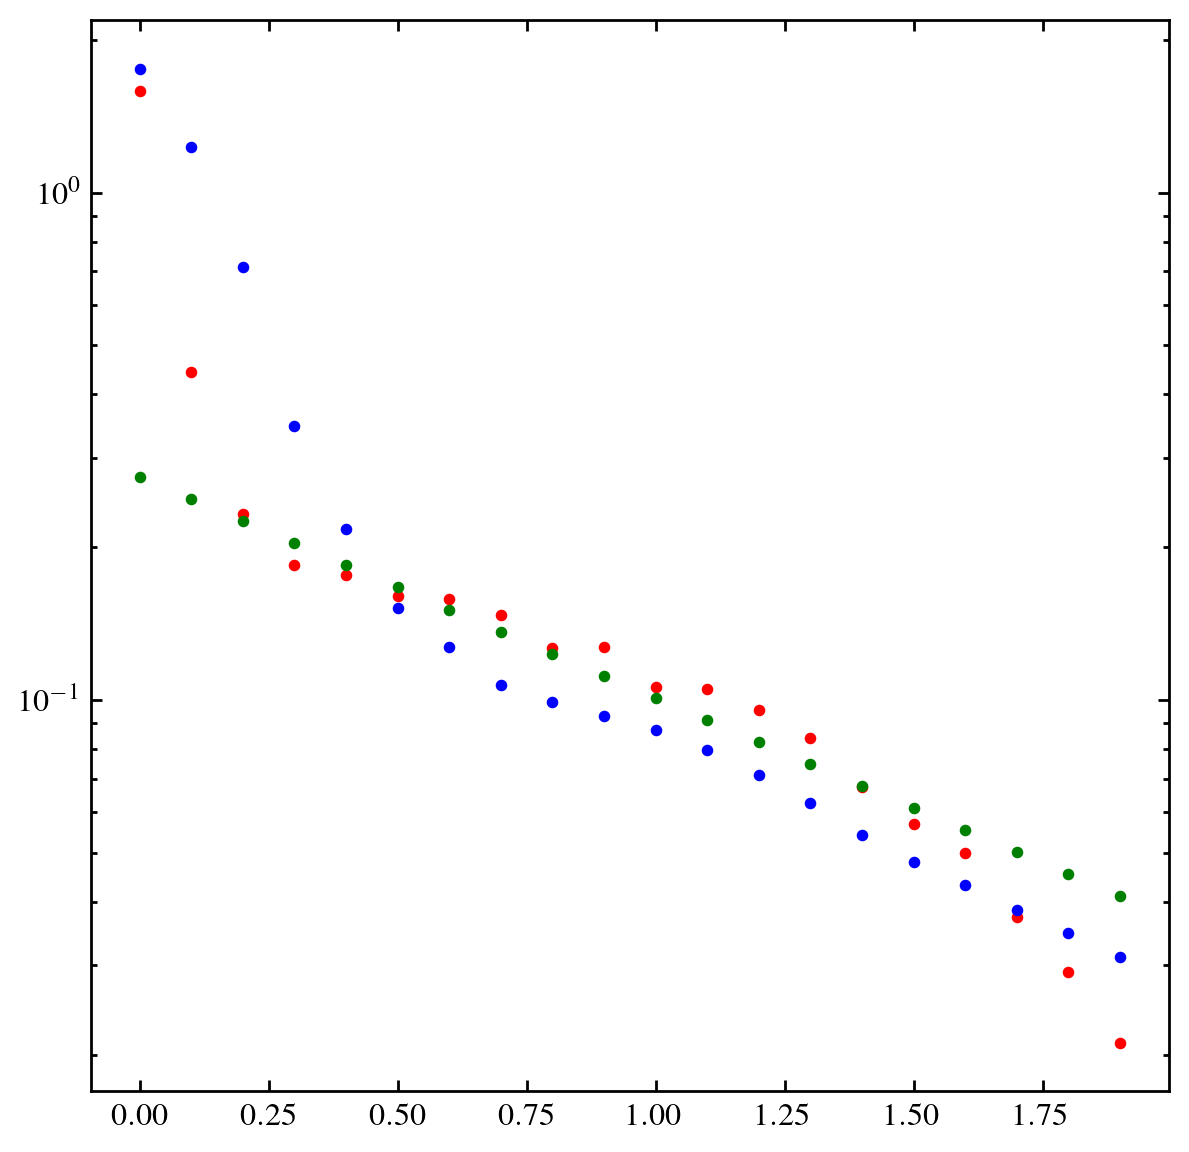

In [21]:
xlo, xhi, xmid, nbin = \
    make_spanning_bins(-0.05,2.0,0.1)
bins = np.append(xlo, xhi[-1])
counts, _ = np.histogram(gmc_sample_merged['size_reff'], bins=bins)
nn_from_counts = counts / math.pi / (xhi**2-xlo**2)
nn_from_counts[0] = counts[0] / math.pi / 0.05**2
pdf_counts = nn_from_counts / np.nansum(counts)

# normalize Ico to 1 
Ico_rad_mean = np.nanmean(Ico_rad_arr, axis=0)
Ico_all_sum = np.nansum(Ico_rad_mean*math.pi*(xhi**2-xlo**2))
pdf_Ico_rad = Ico_rad_mean / Ico_all_sum

# normalize exponential disk to 1
I_exp = np.exp(-xmid)
I_exp_sum = np.nansum(I_exp*math.pi*(xhi**2-xlo**2))
pdf_exp = I_exp / I_exp_sum

fig = plt.figure()
ax = plt.subplot(111)
ax.set_yscale('log')

# number density of GMCs
plt.scatter(xmid, pdf_counts, color='red', s=10, marker='o')

# use the stellar exponential disk
plt.scatter(xmid, pdf_exp, color='green', s=10, marker='o')


plt.scatter(xmid, pdf_Ico_rad, color='blue', s=10, marker='o')

# # save the pdf for different 
pdf_tab = Table()
pdf_tab['rgal_reff'] = xmid
xlo[0] = 0
pdf_tab['rgal_lo'] = xlo
pdf_tab['rgal_hi'] = xhi
pdf_tab['pdf_counts'] = pdf_counts
pdf_tab['pdf_exp'] = pdf_exp
pdf_tab['pdf_rad'] = pdf_Ico_rad

pdf_tab.write('../tables/all_rad_profile.fits', overwrite=True)


Check the two point correlation function for the simulated galaxy

['rad', 'tpcf_exp', 'tpcf_rad']


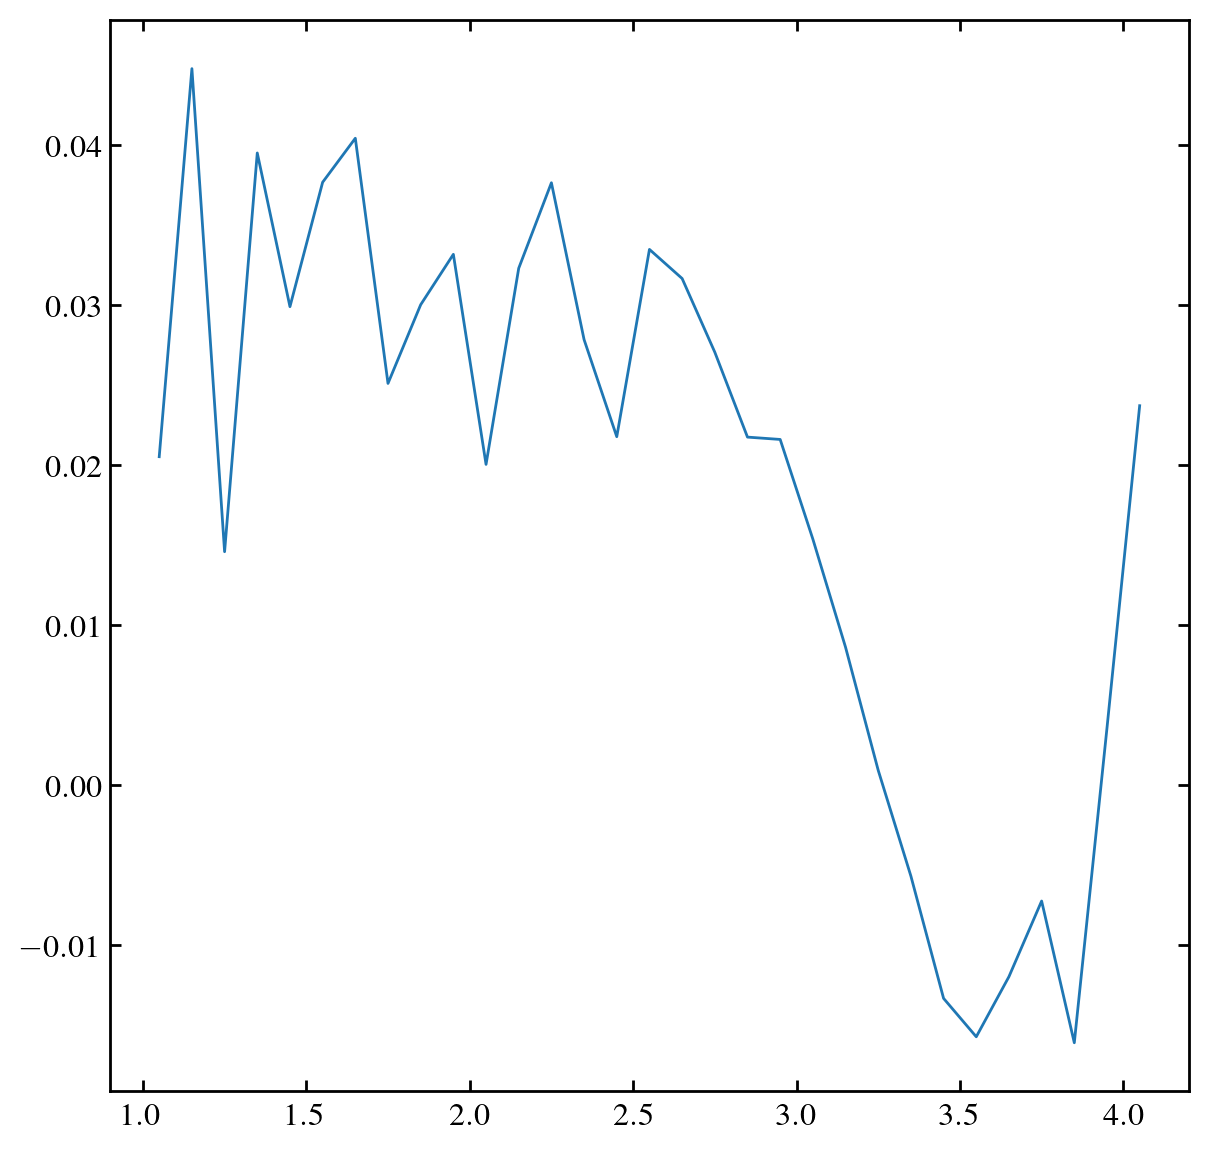

In [22]:
tpcf_amp = np.load("../twopt_for_sim_gal/ndens_rad_exp.npz")
print(tpcf_amp.files)
log_sep = np.log10(tpcf_amp['rad'])
tpcf_ndens_exp = tpcf_amp['tpcf_exp']
tpcf_ndens_rad = tpcf_amp['tpcf_rad']

fig = plt.figure()
# plt.plot(log_sep, np.log10(tpcf_ndens_exp))
plt.plot(log_sep, np.log10(tpcf_ndens_rad))

Check the scale length of a given galaxy

In [23]:
this_row = sample_tab[sample_tab['name']=='ngc1097']
this_dist = this_row['dist'] # in Mpc
this_lstar_kpc = 4.85 * this_dist * this_row['size_scalelength']  / 1000
this_lstar_kpc = this_lstar_kpc[0]
print(this_lstar_kpc)

4.2596436
